# Modeling & Evaluation: Clustering Profil Pertanahan Desa Indonesia

Notebook ini menjalankan tahap **Phase 4 (Modeling)** dan **Phase 5 (Evaluation)** di atas data siap-pakai dari `data/clustering_ready/`.

**Aturan Main dari `data/clustering_ready/README.md`:**
1. Selalu baca `kode8` sebagai teks (`str`) agar *leading zero* tetap terjaga.
2. Gunakan `X_A_scaled.csv` / `X_B_scaled.csv` apa adanya — **jangan rescale ulang**.
3. Kolom di `interpretation_columns.csv` (termasuk banjir, RDTR, tahun) **hanya untuk profiling/evaluasi**, bukan input clustering.
4. Desa di `place_later.csv` tidak dibuang diam-diam: 1.950 desa tanpa persil dilaporkan sebagai kelompok sendiri, dan 122 baris tereksklusi tidak di-*assign*.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial.distance import pdist
from scipy.stats import gaussian_kde
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

plt.rcParams.update({"font.size": 10, "axes.edgecolor": "#444444"})

ROOT = Path.cwd().parent if (Path.cwd().parent / "data" / "clustering_ready").exists() else Path.cwd()
DATA_DIR = ROOT / "data" / "clustering_ready"
OUT_DIR = ROOT / "modeling" / "outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

COMP_COLS = ["s_hak_milik", "s_hgb", "s_hgu", "s_hak_pakai", "s_kosong", "s_other"]
OTHER_COLS = ["log_parcel_density", "log_mean_parcel"]
RAW_SHARE_COLS = [
    "hak_milik_share_luas",
    "hgb_share_luas",
    "hgu_share_luas",
    "hak_pakai_share_luas",
    "kosong_share_luas",
    "other_share_luas",
]
SHARE_LABELS = {
    "hak_milik_share_luas": "Hak Milik (SHM)",
    "hgb_share_luas": "HGB",
    "hgu_share_luas": "HGU",
    "hak_pakai_share_luas": "Hak Pakai",
    "kosong_share_luas": "Kosong (Belum Hak)",
    "other_share_luas": "Lainnya (<1%)",
}

read_opts = dict(index_col="kode8", dtype={"kode8": str})
x_a_scaled = pd.read_csv(DATA_DIR / "X_A_scaled.csv", **read_opts)
x_a = pd.read_csv(DATA_DIR / "X_A.csv", **read_opts)
village_ids = pd.read_csv(DATA_DIR / "village_ids.csv", **read_opts)
interp = pd.read_csv(DATA_DIR / "interpretation_columns.csv", **read_opts)
place_later = pd.read_csv(DATA_DIR / "place_later.csv", **read_opts)
with open(DATA_DIR / "transform_recipe.json", encoding="utf-8") as f:
    recipe = json.load(f)

print(f"X_A_scaled : {x_a_scaled.shape}")
print(f"village_ids: {village_ids.shape}")
print(f"interp     : {interp.shape}")
print(f"place_later: {place_later.shape}")
x_a_scaled.head()

X_A_scaled : (77770, 8)
village_ids: (79842, 7)
interp     : (79842, 33)
place_later: (2744, 20)


,s_hak_milik,s_hgb,s_hgu,s_hak_pakai,s_kosong,s_other,log_parcel_density,log_mean_parcel
kode8,,,,,,,,
01010101,-1.415300,0.137282,-0.165198,2.642250,0.166919,-0.126676,0.533604,0.048824
01010102,-0.691650,0.116154,-0.165198,2.740160,-0.845902,0.032075,0.656693,-0.348591
01010103,0.405771,0.574030,-0.165198,0.551607,0.131875,-0.014368,1.115330,-1.109440
01010104,-1.324440,0.674642,-0.165198,2.548420,0.049517,0.187414,0.864807,-0.559651
01010105,0.111128,0.567090,-0.165198,1.620670,-0.367027,0.150282,1.270550,-1.291960


## Step 1: Cek Ombak — Kenalan sama `X_A_scaled.csv` & Uji *Cluster Tendency*

Sebelum memanggil algoritma clustering, kita cek dulu integritas matriks, sebaran varians fitur, contoh desa nyata, struktur ruang PCA, serta kecenderungan berkelompok (*cluster tendency*).

In [2]:
# 1.1 Sanity checks & verifikasi transform_recipe.json
assert x_a_scaled.shape == (77770, 8), f"Unexpected shape: {x_a_scaled.shape}"
assert x_a.shape == (77770, 8), f"Unexpected X_A shape: {x_a.shape}"
assert list(x_a_scaled.columns) == COMP_COLS + OTHER_COLS
assert x_a_scaled.index.equals(x_a.index), "Index mismatch X_A_scaled vs X_A"
assert not x_a_scaled.isna().any().any(), "NaN found in X_A_scaled"
assert np.isfinite(x_a_scaled.to_numpy()).all(), "Inf found in X_A_scaled"
assert (x_a_scaled.index.str.len() == 8).all(), "kode8 length is not 8"
assert x_a_scaled.index.is_unique, "Duplicate kode8 in X_A_scaled"
assert x_a_scaled.index.isin(village_ids.index).all()
assert x_a_scaled.index.isin(interp.index).all()

sc_a = recipe["scaling"]["A"]
rebuilt = pd.DataFrame(index=x_a.index)
for col in sc_a["comp_cols"]:
    rebuilt[col] = (x_a[col] - sc_a["comp_center"][col]) * sc_a["comp_factor"]
for col in sc_a["other_cols"]:
    rebuilt[col] = (x_a[col] - sc_a["center"][col]) / sc_a["scale"][col]
max_rebuild_diff = float(np.max(np.abs(rebuilt[x_a_scaled.columns] - x_a_scaled).to_numpy()))

vars_series = x_a_scaled.var(ddof=1)
comp_var = float(vars_series[COMP_COLS].sum())
other_var = float(vars_series[OTHER_COLS].sum())
total_var = comp_var + other_var

print(f"Leading-zero kode8 preserved : {int(x_a_scaled.index.str.startswith('0').sum()):,} baris")
print(f"Max diff rebuild vs recipe   : {max_rebuild_diff:.2e}")
print(
    f"Varians Komposisi (6 kolom)  : {comp_var:.3f} ({100*comp_var/total_var:.1f}%) | "
    f"Density+Size (2 kolom): {other_var:.3f} ({100*other_var/total_var:.1f}%)"
)

col_stats = pd.DataFrame({
    "median": x_a_scaled.median(),
    "mean": x_a_scaled.mean(),
    "std": x_a_scaled.std(ddof=1),
    "var": vars_series,
    "p05": x_a_scaled.quantile(0.05),
    "p95": x_a_scaled.quantile(0.95),
}).round(4)
display(col_stats)

meta_fit = village_ids.join(interp, how="inner").loc[x_a_scaled.index]
dom_counts = meta_fit[RAW_SHARE_COLS].idxmax(axis=1).map(SHARE_LABELS).value_counts()
dom_df = pd.DataFrame({
    "jumlah_desa": dom_counts,
    "persen": (dom_counts / len(meta_fit) * 100).round(2),
})
print("\nTipe wilayah di fit set A:", meta_fit["tipe"].value_counts().to_dict())
display(dom_df)

Leading-zero kode8 preserved : 24,852 baris
Max diff rebuild vs recipe   : 1.35e-05
Varians Komposisi (6 kolom)  : 5.000 (70.1%) | Density+Size (2 kolom): 2.134 (29.9%)


,median,mean,std,var,p05,p95
s_hak_milik,0.2974,-0.0000,1.1851,1.4045,-2.5241,1.3382
s_hgb,-0.2844,0.0000,0.6070,0.3684,-0.2844,1.3007
s_hgu,-0.1652,-0.0000,0.7183,0.5159,-0.1652,1.1360
s_hak_pakai,-0.2655,0.0000,0.8430,0.7107,-0.7479,1.6077
s_kosong,0.0584,-0.0000,1.3811,1.9074,-2.1263,2.1487
s_other,-0.1267,0.0000,0.3050,0.0930,-0.1267,0.3554
log_parcel_density,0.0000,-0.1532,0.9916,0.9832,-2.0228,1.0861
log_mean_parcel,0.0000,0.1602,1.0726,1.1504,-1.2704,1.9054



Tipe wilayah di fit set A: {'Desa': 62361, 'Kelurahan': 15409}


,jumlah_desa,persen
Hak Milik (SHM),47458,61.02
Kosong (Belum Hak),24405,31.38
Hak Pakai,2417,3.11
HGU,2281,2.93
HGB,969,1.25
Lainnya (<1%),240,0.31


In [3]:
# 1.2 Contoh 5 desa nyata yang mewakili karakter ekstrem & transisi
queries = [
    (
        "Kelurahan Urban (SHM + HGB tinggi)",
        (meta_fit["tipe"] == "Kelurahan")
        & (meta_fit["hak_milik_share_luas"] > 0.70)
        & (meta_fit["hgb_share_luas"] > 0.12)
        & (meta_fit["jumlah_persil"] >= 1000),
        "jumlah_persil",
    ),
    (
        "Desa Dominan Kosong (Belum Bersertifikat)",
        (meta_fit["tipe"] == "Desa")
        & (meta_fit["kosong_share_luas"] > 0.92)
        & (meta_fit["jumlah_persil"] >= 200),
        "jumlah_persil",
    ),
    (
        "Desa Perkebunan (Dominan HGU)",
        (meta_fit["hgu_share_luas"] > 0.85) & (meta_fit["jumlah_persil"] >= 20),
        "hgu_share_luas",
    ),
    (
        "Wilayah Dominan Hak Pakai (Pemerintah/Fasum)",
        (meta_fit["hak_pakai_share_luas"] > 0.75) & (meta_fit["jumlah_persil"] >= 30),
        "jumlah_persil",
    ),
    (
        "Desa Campuran / Transisi (SHM ~50% + Kosong ~45%)",
        (meta_fit["tipe"] == "Desa")
        & (meta_fit["hak_milik_share_luas"].between(0.45, 0.55))
        & (meta_fit["kosong_share_luas"].between(0.40, 0.50))
        & (meta_fit["jumlah_persil"] >= 500),
        "jumlah_persil",
    ),
]

example_rows = []
examples_json = []
for label, mask, sort_col in queries:
    sub = meta_fit.loc[mask].sort_values(sort_col, ascending=False)
    pick_idx = len(sub) // 2 if "Campuran" in label else 0
    kode8 = str(sub.index[pick_idx])
    r = sub.iloc[pick_idx]
    example_rows.append({
        "profil": label,
        "kode8": kode8,
        "nama": r["nama"],
        "tipe": r["tipe"],
        "kabupaten": r["kabupaten"],
        "provinsi": r["provinsi"],
        "persil": int(r["jumlah_persil"]),
        "SHM%": round(r["hak_milik_share_luas"] * 100, 1),
        "Kosong%": round(r["kosong_share_luas"] * 100, 1),
        "HGB%": round(r["hgb_share_luas"] * 100, 1),
        "HGU%": round(r["hgu_share_luas"] * 100, 1),
        "Pakai%": round(r["hak_pakai_share_luas"] * 100, 1),
    })
    examples_json.append({
        "profile": label,
        "kode8": kode8,
        "nama": str(r["nama"]),
        "kecamatan": str(r["kecamatan"]),
        "kabupaten": str(r["kabupaten"]),
        "provinsi": str(r["provinsi"]),
        "tipe": str(r["tipe"]),
        "jumlah_persil": int(r["jumlah_persil"]),
        "luas_desa_ha": float(r["luas_desa"] / 10000.0),
        "raw_shares": {
            "hak_milik": float(r["hak_milik_share_luas"]),
            "hgb": float(r["hgb_share_luas"]),
            "hgu": float(r["hgu_share_luas"]),
            "hak_pakai": float(r["hak_pakai_share_luas"]),
            "kosong": float(r["kosong_share_luas"]),
            "other": float(r["other_share_luas"]),
        },
        "scaled_values": {k: float(v) for k, v in x_a_scaled.loc[kode8].items()},
    })

display(pd.DataFrame(example_rows))

,profil,kode8,nama,tipe,kabupaten,provinsi,persil,SHM%,Kosong%,HGB%,HGU%,Pakai%
0,Kelurahan Urban (SHM + HGB tinggi),06010903,Mayang Mangurai,Kelurahan,Kota Jambi,Jambi,13927,77.8,3.2,15.2,0.0,3.6
1,Desa Dominan Kosong (Belum Bersertifikat),12301108,Arjowilangun,Desa,Malang,Jawa Timur,11812,1.2,98.4,0.3,0.0,0.1
2,Desa Perkebunan (Dominan HGU),16090306,Mulupan,Desa,Kutai Timur,Kalimantan Timur,32,0.0,0.0,0.0,100.0,0.0
3,Wilayah Dominan Hak Pakai (Pemerintah/Fasum),05050101,Bangkinang,Kelurahan,KAMPAR,Riau,5172,4.9,11.1,0.3,0.0,83.8
4,Desa Campuran / Transisi (SHM ~50% + Kosong ~45%),11260808,Tanjungrejo,Desa,Purworejo,Jawa Tengah,2051,46.5,40.4,0.0,0.0,12.4


,Varians (%),Kumulatif (%)
PC1,39.66,39.66
PC2,27.98,67.64
PC3,13.51,81.16
PC4,7.48,88.64
PC5,4.91,93.55
PC6,3.58,97.12
PC7,1.75,98.88
PC8,1.12,100.00


,PC1,PC2,PC3,PC4
s_hak_milik,-0.608,-0.120,-0.528,-0.168
s_hgb,-0.025,-0.096,0.202,0.293
s_hgu,0.060,0.259,0.040,0.739
s_hak_pakai,-0.117,-0.052,0.749,-0.251
s_kosong,0.744,-0.341,-0.236,-0.232
s_other,-0.013,-0.031,0.046,0.041
log_parcel_density,-0.004,-0.619,-0.085,0.470
log_mean_parcel,0.241,0.637,-0.230,0.027


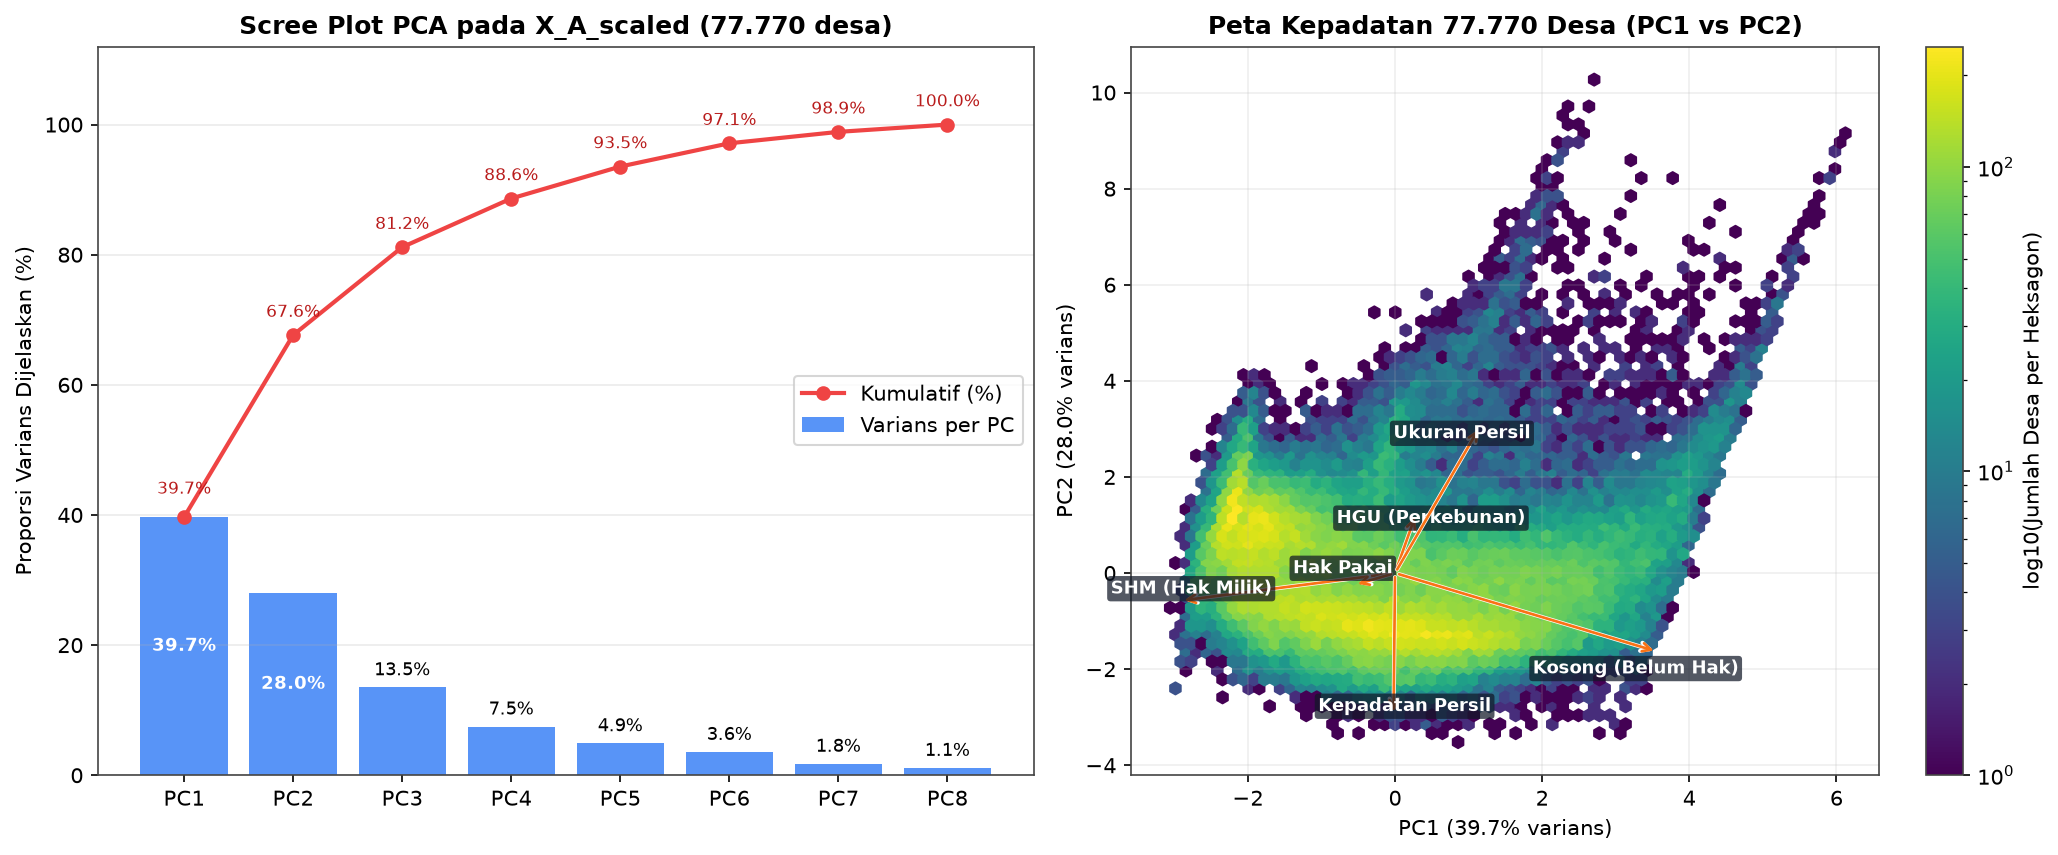

In [4]:
# 1.3 PCA pada seluruh 77.770 desa + Peta Kepadatan 2D
pca = PCA(n_components=x_a_scaled.shape[1], random_state=42)
pca_scores = pca.fit_transform(x_a_scaled.to_numpy())

ev_pct = pca.explained_variance_ratio_ * 100.0
cum_pct = np.cumsum(ev_pct)
pca_var_df = pd.DataFrame(
    {"Varians (%)": ev_pct.round(2), "Kumulatif (%)": cum_pct.round(2)},
    index=[f"PC{i}" for i in range(1, 9)],
)
loadings_df = pd.DataFrame(
    pca.components_[:4].T,
    index=x_a_scaled.columns,
    columns=["PC1", "PC2", "PC3", "PC4"],
).round(3)

display(pca_var_df)
display(loadings_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.8), dpi=150)
pcs = np.arange(1, len(ev_pct) + 1)
ax0 = axes[0]
bars = ax0.bar(pcs, ev_pct, color="#3b82f6", alpha=0.85, label="Varians per PC")
ax0.plot(pcs, cum_pct, color="#ef4444", marker="o", linewidth=2, label="Kumulatif (%)")
for bar, val in zip(bars, ev_pct):
    if val >= 20.0:
        ax0.text(bar.get_x() + bar.get_width() / 2, val / 2, f"{val:.1f}%",
                 ha="center", va="center", fontsize=8.5, fontweight="bold", color="white")
    else:
        ax0.text(bar.get_x() + bar.get_width() / 2, val + 1.2, f"{val:.1f}%",
                 ha="center", va="bottom", fontsize=8.5)
for idx_pc, (x_i, y_i) in enumerate(zip(pcs, cum_pct)):
    y_off = 3.0 if idx_pc == 0 else 2.2
    ax0.text(x_i, y_i + y_off, f"{y_i:.1f}%", ha="center", va="bottom", fontsize=8, color="#b91c1c")
ax0.set_xticks(pcs)
ax0.set_xticklabels([f"PC{i}" for i in pcs])
ax0.set_ylim(0, 112)
ax0.set_ylabel("Proporsi Varians Dijelaskan (%)")
ax0.set_title("Scree Plot PCA pada X_A_scaled (77.770 desa)", fontweight="bold")
ax0.legend(loc="center right", frameon=True)
ax0.grid(axis="y", alpha=0.25)

ax1 = axes[1]
hb = ax1.hexbin(pca_scores[:, 0], pca_scores[:, 1], gridsize=65, bins="log", cmap="viridis", mincnt=1)
cb = fig.colorbar(hb, ax=ax1)
cb.set_label("log10(Jumlah Desa per Heksagon)")

arrow_cols = [
    ("s_hak_milik", "SHM (Hak Milik)", (0.15, 0.25)),
    ("s_kosong", "Kosong (Belum Hak)", (-0.30, -0.35)),
    ("s_hgu", "HGU (Perkebunan)", (0.20, -0.10)),
    ("s_hak_pakai", "Hak Pakai", (-0.15, 0.35)),
    ("log_parcel_density", "Kepadatan Persil", (0.15, 0.20)),
    ("log_mean_parcel", "Ukuran Persil", (-0.25, -0.15)),
]
scale_arrow = 4.8
for col_name, label, offset in arrow_cols:
    j = list(x_a_scaled.columns).index(col_name)
    dx = pca.components_[0, j] * scale_arrow
    dy = pca.components_[1, j] * scale_arrow
    ax1.annotate("", xy=(dx, dy), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="#ffffff", lw=2.0))
    ax1.annotate("", xy=(dx, dy), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="#f97316", lw=1.3))
    ax1.text(
        dx + offset[0], dy + offset[1], label, color="white", fontsize=8.5, fontweight="bold",
        ha="center", va="center", bbox=dict(boxstyle="round,pad=0.2", fc="#111827", alpha=0.72, ec="none"),
    )
ax1.set_xlabel(f"PC1 ({ev_pct[0]:.1f}% varians)")
ax1.set_ylabel(f"PC2 ({ev_pct[1]:.1f}% varians)")
ax1.set_title("Peta Kepadatan 77.770 Desa (PC1 vs PC2)", fontweight="bold")
ax1.grid(alpha=0.2)

fig.tight_layout()
plt.show()

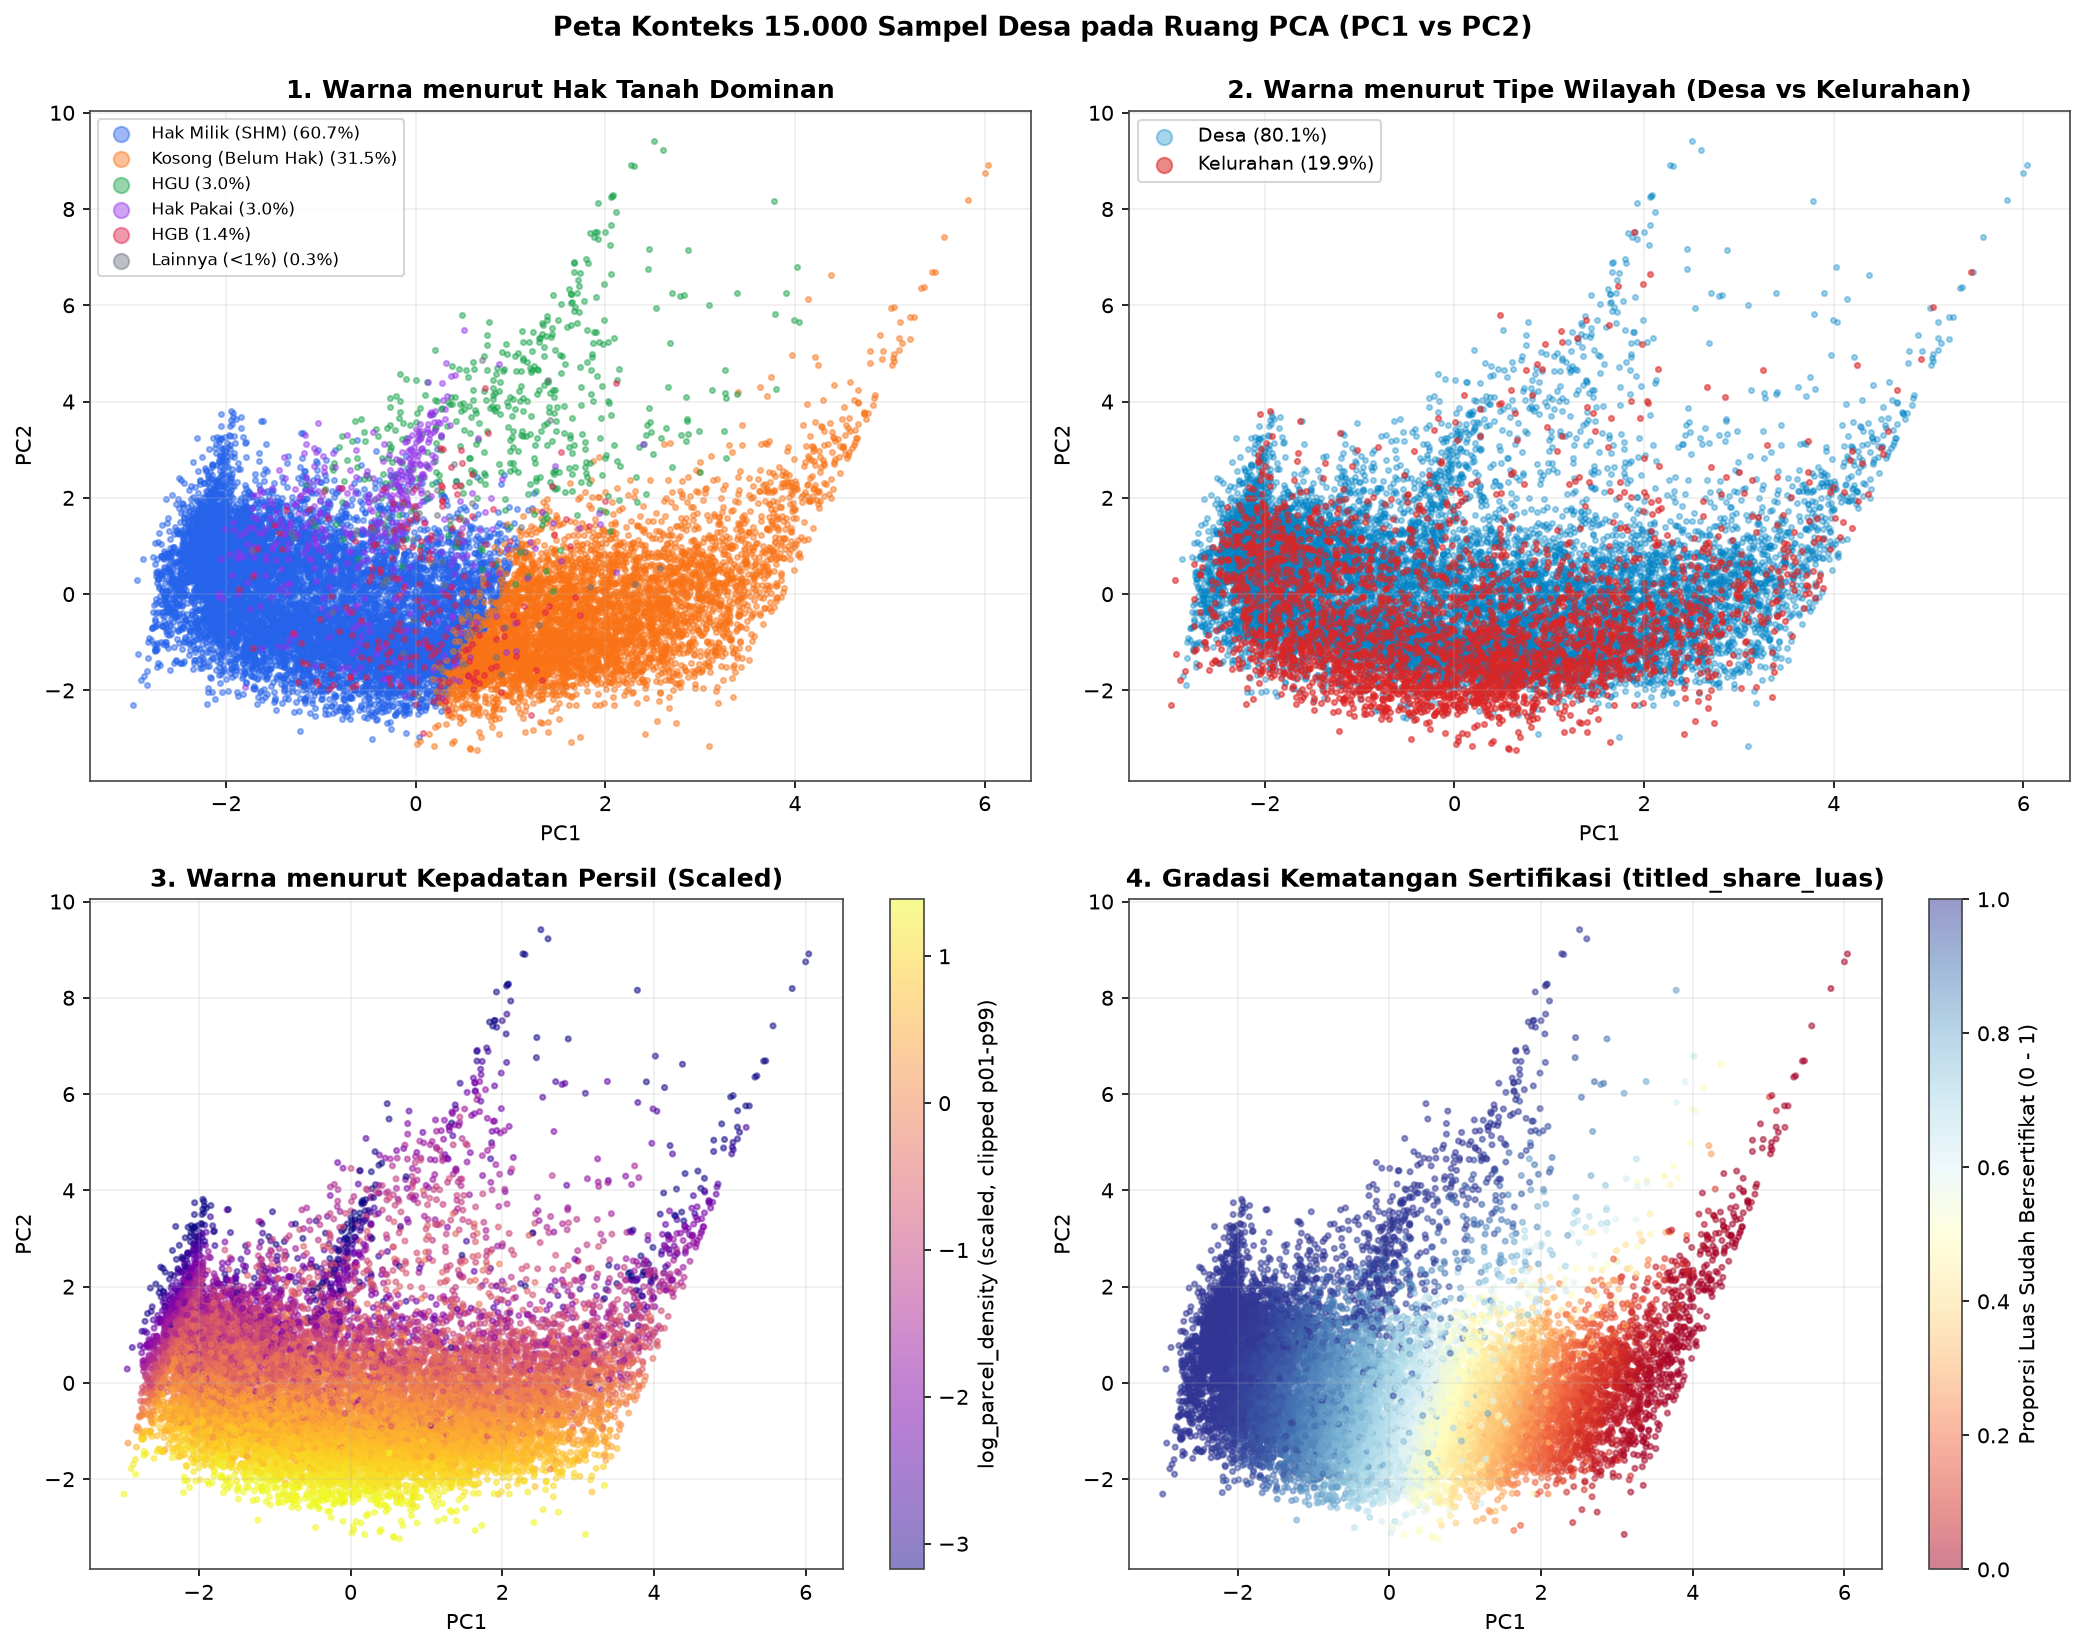

In [5]:
# 1.4 Peta Konteks pada 15.000 sampel desa (seed=42)
rng = np.random.default_rng(42)
sample_pos = rng.choice(len(x_a_scaled), size=15000, replace=False)
sample_ids = x_a_scaled.index[sample_pos]
meta_s = meta_fit.loc[sample_ids]
x_s = x_a_scaled.loc[sample_ids]
pc1_s = pca_scores[sample_pos, 0]
pc2_s = pca_scores[sample_pos, 1]

fig, axes = plt.subplots(2, 2, figsize=(14, 11), dpi=150)

ax = axes[0, 0]
dom = meta_s[RAW_SHARE_COLS].idxmax(axis=1).map(SHARE_LABELS)
palette = {
    "Hak Milik (SHM)": "#2563eb",
    "Kosong (Belum Hak)": "#f97316",
    "HGU": "#16a34a",
    "Hak Pakai": "#9333ea",
    "HGB": "#e11d48",
    "Lainnya (<1%)": "#6b7280",
}
for label_name, color in palette.items():
    mask = dom == label_name
    if mask.any():
        ax.scatter(pc1_s[mask], pc2_s[mask], s=6, alpha=0.45, color=color,
                   label=f"{label_name} ({mask.mean()*100:.1f}%)", rasterized=True)
ax.set_title("1. Warna menurut Hak Tanah Dominan", fontweight="bold")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.legend(markerscale=3, fontsize=8, loc="upper left", frameon=True)
ax.grid(alpha=0.2)

ax = axes[0, 1]
for tipe_val, color, alpha in [("Desa", "#0284c7", 0.35), ("Kelurahan", "#dc2626", 0.55)]:
    mask = meta_s["tipe"] == tipe_val
    ax.scatter(pc1_s[mask], pc2_s[mask], s=6, alpha=alpha, color=color,
               label=f"{tipe_val} ({mask.mean()*100:.1f}%)", rasterized=True)
ax.set_title("2. Warna menurut Tipe Wilayah (Desa vs Kelurahan)", fontweight="bold")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.legend(markerscale=3, fontsize=9, loc="upper left", frameon=True)
ax.grid(alpha=0.2)

ax = axes[1, 0]
dens_vals = x_s["log_parcel_density"].to_numpy()
vmin, vmax = np.quantile(dens_vals, [0.01, 0.99])
sc3 = ax.scatter(pc1_s, pc2_s, c=np.clip(dens_vals, vmin, vmax), cmap="plasma", s=6, alpha=0.5, rasterized=True)
fig.colorbar(sc3, ax=ax, label="log_parcel_density (scaled, clipped p01-p99)")
ax.set_title("3. Warna menurut Kepadatan Persil (Scaled)", fontweight="bold")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.grid(alpha=0.2)

ax = axes[1, 1]
sc4 = ax.scatter(pc1_s, pc2_s, c=meta_s["titled_share_luas"].to_numpy(), cmap="RdYlBu",
                 vmin=0, vmax=1, s=6, alpha=0.5, rasterized=True)
fig.colorbar(sc4, ax=ax, label="Proporsi Luas Sudah Bersertifikat (0 - 1)")
ax.set_title("4. Gradasi Kematangan Sertifikasi (titled_share_luas)", fontweight="bold")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.grid(alpha=0.2)

fig.suptitle("Peta Konteks 15.000 Sampel Desa pada Ruang PCA (PC1 vs PC2)", fontsize=13, fontweight="bold", y=0.995)
fig.tight_layout()
plt.show()

,Metode,Mean,SD,Min,Max
0,8D Bounding Box (naif),0.9525,0.0017,0.9503,0.9550
1,PCA-4D (p01-p99),0.8863,0.0024,0.8833,0.8907
2,Simplex-Aware Null (Dirichlet),0.9046,0.0029,0.9005,0.9085


Pairwise distance (n=3,000) median=3.16, p10=1.46, p90=5.69
10-NN distance (n=10,000)   median=0.278, p10=0.156, p90=0.622


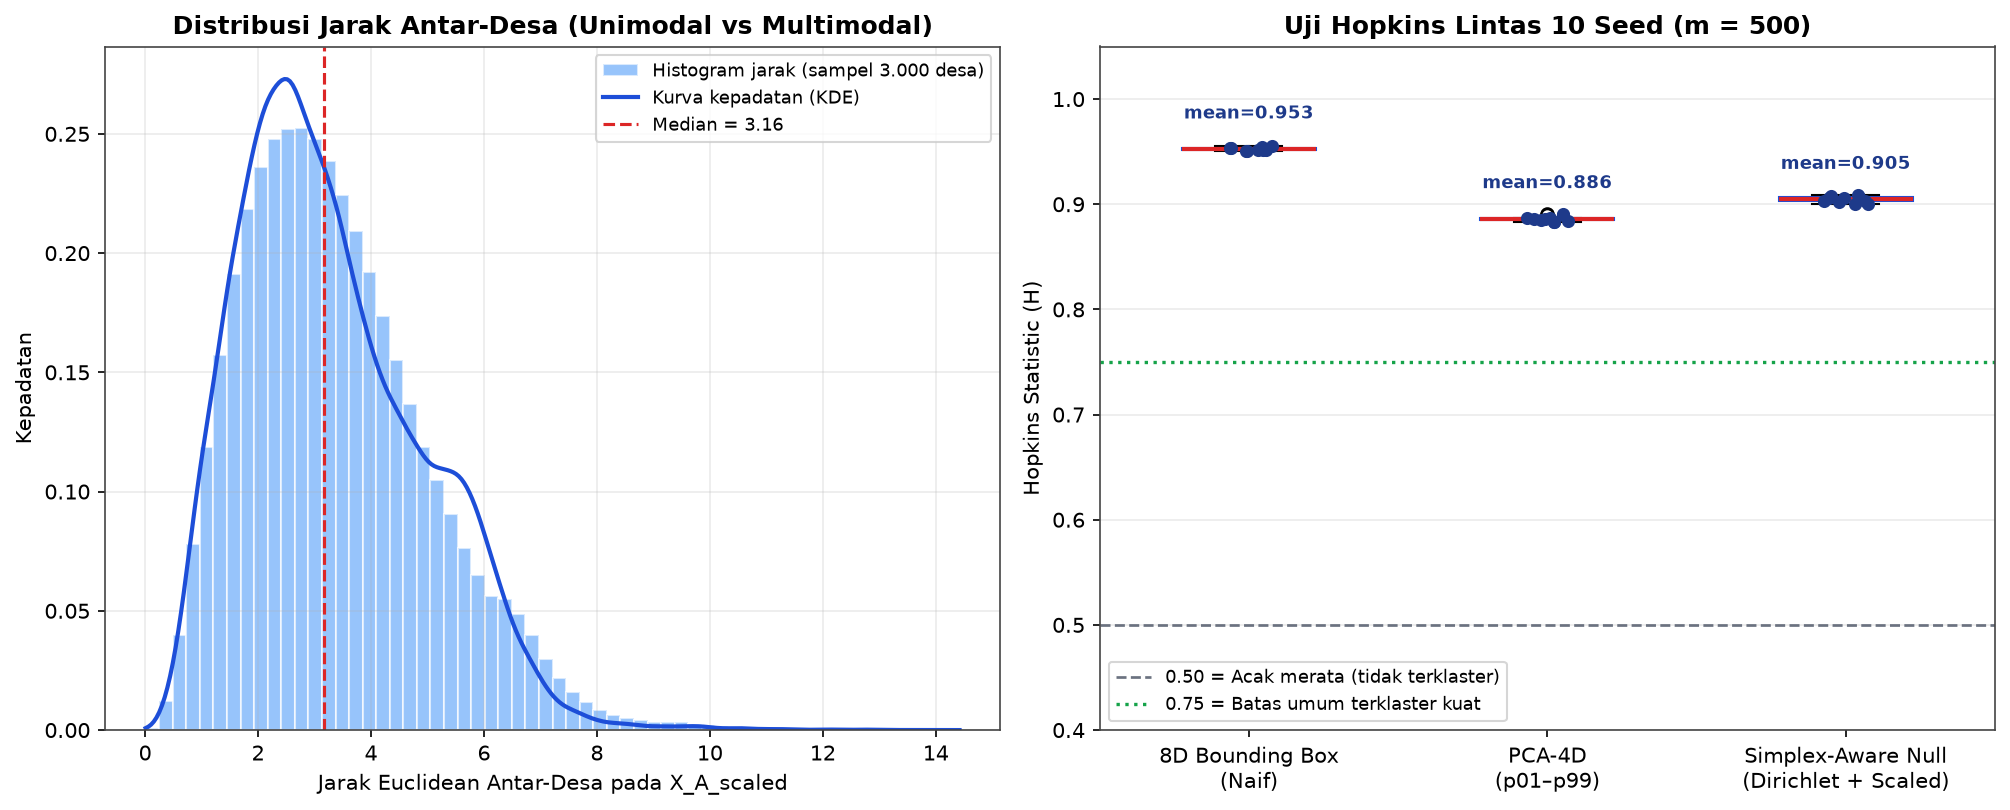

Saved: /Users/otnansirk/S2-MMI/DATA-SCIENCE/spatial-pertanahan-nasional/modeling/outputs/step1_summary.json


In [6]:
# 1.5 Uji Cluster Tendency: Hopkins 3 Versi (10 seed, m=500) & Distribusi Jarak
def compute_hopkins_from_samples(x_real_all, x_real_sample, x_synth):
    nn_real = NearestNeighbors(n_neighbors=2, metric="euclidean").fit(x_real_all)
    w_dists, _ = nn_real.kneighbors(x_real_sample)
    w = w_dists[:, 1]
    nn_synth = NearestNeighbors(n_neighbors=1, metric="euclidean").fit(x_real_all)
    u_dists, _ = nn_synth.kneighbors(x_synth)
    u = u_dists[:, 0]
    denom = float(np.sum(u) + np.sum(w))
    return float(np.sum(u) / denom) if denom > 0 else float("nan")

x_arr = x_a_scaled.to_numpy()
pca4_arr = pca_scores[:, :4]
mins_8d, maxs_8d = x_arr.min(axis=0), x_arr.max(axis=0)
p01_pc4, p99_pc4 = np.quantile(pca4_arr, 0.01, axis=0), np.quantile(pca4_arr, 0.99, axis=0)
dens_p01, dens_p99 = x_a["log_parcel_density"].quantile([0.01, 0.99]).to_numpy()
size_p01, size_p99 = x_a["log_mean_parcel"].quantile([0.01, 0.99]).to_numpy()

comp_centers = np.array([sc_a["comp_center"][c] for c in sc_a["comp_cols"]])
comp_factor = float(sc_a["comp_factor"])
dens_center, dens_scale = float(sc_a["center"]["log_parcel_density"]), float(sc_a["scale"]["log_parcel_density"])
size_center, size_scale = float(sc_a["center"]["log_mean_parcel"]), float(sc_a["scale"]["log_mean_parcel"])

hopkins_8d, hopkins_pca4, hopkins_simplex = [], [], []
m = 500
for seed in range(42, 52):
    rng_s = np.random.default_rng(seed)
    idx = rng_s.choice(len(x_arr), size=m, replace=False)
    hopkins_8d.append(compute_hopkins_from_samples(x_arr, x_arr[idx], rng_s.uniform(mins_8d, maxs_8d, size=(m, x_arr.shape[1]))))
    hopkins_pca4.append(compute_hopkins_from_samples(pca4_arr, pca4_arr[idx], rng_s.uniform(p01_pc4, p99_pc4, size=(m, 4))))
    s_comp_scaled = (np.sqrt(rng_s.dirichlet(np.ones(6), size=m)) - comp_centers) * comp_factor
    s_dens = (rng_s.uniform(dens_p01, dens_p99, size=(m, 1)) - dens_center) / dens_scale
    s_size = (rng_s.uniform(size_p01, size_p99, size=(m, 1)) - size_center) / size_scale
    hopkins_simplex.append(compute_hopkins_from_samples(x_arr, x_arr[idx], np.hstack([s_comp_scaled, s_dens, s_size])))

rng42 = np.random.default_rng(42)
pairwise_dists = pdist(x_arr[rng42.choice(len(x_arr), size=3000, replace=False)], metric="euclidean")
nn10 = NearestNeighbors(n_neighbors=11, metric="euclidean").fit(x_arr)
d10, _ = nn10.kneighbors(x_arr[rng42.choice(len(x_arr), size=10000, replace=False)])
knn10_dists = d10[:, 10]

hopkins_table = pd.DataFrame([
    {"Metode": "8D Bounding Box (naif)", "Mean": np.mean(hopkins_8d), "SD": np.std(hopkins_8d, ddof=1), "Min": np.min(hopkins_8d), "Max": np.max(hopkins_8d)},
    {"Metode": "PCA-4D (p01-p99)", "Mean": np.mean(hopkins_pca4), "SD": np.std(hopkins_pca4, ddof=1), "Min": np.min(hopkins_pca4), "Max": np.max(hopkins_pca4)},
    {"Metode": "Simplex-Aware Null (Dirichlet)", "Mean": np.mean(hopkins_simplex), "SD": np.std(hopkins_simplex, ddof=1), "Min": np.min(hopkins_simplex), "Max": np.max(hopkins_simplex)},
]).round(4)
display(hopkins_table)
print(f"Pairwise distance (n=3,000) median={np.median(pairwise_dists):.2f}, p10={np.quantile(pairwise_dists, 0.1):.2f}, p90={np.quantile(pairwise_dists, 0.9):.2f}")
print(f"10-NN distance (n=10,000)   median={np.median(knn10_dists):.3f}, p10={np.quantile(knn10_dists, 0.1):.3f}, p90={np.quantile(knn10_dists, 0.9):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5), dpi=150)
ax0 = axes[0]
ax0.hist(pairwise_dists, bins=60, density=True, color="#60a5fa", alpha=0.65, edgecolor="white", label="Histogram jarak (sampel 3.000 desa)")
kde = gaussian_kde(pairwise_dists[:100000])
xs = np.linspace(pairwise_dists.min(), pairwise_dists.max(), 300)
ax0.plot(xs, kde(xs), color="#1d4ed8", lw=2, label="Kurva kepadatan (KDE)")
med_d = float(np.median(pairwise_dists))
ax0.axvline(med_d, color="#dc2626", ls="--", lw=1.5, label=f"Median = {med_d:.2f}")
ax0.set_xlabel("Jarak Euclidean Antar-Desa pada X_A_scaled")
ax0.set_ylabel("Kepadatan")
ax0.set_title("Distribusi Jarak Antar-Desa (Unimodal vs Multimodal)", fontweight="bold")
ax0.legend(frameon=True, fontsize=8.5)
ax0.grid(alpha=0.25)

ax1 = axes[1]
methods = [
    ("8D Bounding Box\n(Naif)", hopkins_8d),
    ("PCA-4D\n(p01–p99)", hopkins_pca4),
    ("Simplex-Aware Null\n(Dirichlet + Scaled)", hopkins_simplex),
]
positions = [1, 2, 3]
ax1.boxplot([v for _, v in methods], positions=positions, widths=0.45, patch_artist=True,
            boxprops=dict(facecolor="#dbeafe", color="#1d4ed8"), medianprops=dict(color="#dc2626", linewidth=2))
rng_plot = np.random.default_rng(42)
for pos, (_, vals) in zip(positions, methods):
    ax1.scatter(np.full(len(vals), pos) + rng_plot.uniform(-0.08, 0.08, size=len(vals)), vals, color="#1e3a8a", s=28, zorder=3)
    ax1.text(pos, float(np.mean(vals)) + 0.025, f"mean={np.mean(vals):.3f}", ha="center", va="bottom", fontsize=8.5, fontweight="bold", color="#1e3a8a")
ax1.axhline(0.50, color="#6b7280", ls="--", lw=1.3, label="0.50 = Acak merata (tidak terklaster)")
ax1.axhline(0.75, color="#16a34a", ls=":", lw=1.6, label="0.75 = Batas umum terklaster kuat")
ax1.set_xticks(positions)
ax1.set_xticklabels([name for name, _ in methods])
ax1.set_ylim(0.40, 1.05)
ax1.set_ylabel("Hopkins Statistic (H)")
ax1.set_title("Uji Hopkins Lintas 10 Seed (m = 500)", fontweight="bold")
ax1.legend(loc="lower left", frameon=True, fontsize=8.5)
ax1.grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()

def summarize_arr(vals):
    arr = np.asarray(vals, dtype=float)
    return {"mean": float(arr.mean()), "std": float(arr.std(ddof=1)), "median": float(np.median(arr)),
            "min": float(arr.min()), "max": float(arr.max()), "p10": float(np.quantile(arr, 0.10)), "p90": float(np.quantile(arr, 0.90))}

summary = {
    "sanity": {
        "n_rows": int(x_a_scaled.shape[0]),
        "n_cols": int(x_a_scaled.shape[1]),
        "leading_zero_kode8_count": int(x_a_scaled.index.str.startswith("0").sum()),
        "max_recipe_rebuild_diff": max_rebuild_diff,
        "comp_variance": comp_var,
        "other_variance": other_var,
        "total_variance": total_var,
        "comp_variance_pct": float(100.0 * comp_var / total_var),
        "other_variance_pct": float(100.0 * other_var / total_var),
    },
    "context_breakdown": {
        "dominant_right_counts": {str(k): int(v) for k, v in dom_counts.items()},
        "dominant_right_pct": {str(k): float(v) for k, v in (dom_counts / len(meta_fit) * 100).round(2).items()},
        "tipe_counts": {str(k): int(v) for k, v in meta_fit["tipe"].value_counts().items()},
    },
    "examples": examples_json,
    "pca": {
        "explained_variance_ratio": [float(x) for x in pca.explained_variance_ratio_],
        "cumulative_variance_ratio": [float(x) for x in np.cumsum(pca.explained_variance_ratio_)],
    },
    "tendency": {
        "n_seeds": 10,
        "sample_m": m,
        "hopkins_8d_box": summarize_arr(hopkins_8d) | {"values": hopkins_8d},
        "hopkins_pca4_p01_p99": summarize_arr(hopkins_pca4) | {"values": hopkins_pca4},
        "hopkins_simplex_null": summarize_arr(hopkins_simplex) | {"values": hopkins_simplex},
        "pairwise_dist_3k": summarize_arr(pairwise_dists),
        "knn10_dist_10k": summarize_arr(knn10_dists),
    },
    "place_later_rows": int(len(place_later)),
}
with open(OUT_DIR / "step1_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)
print("Saved:", OUT_DIR / "step1_summary.json")

### Vonis Step 1
- **Hopkins jujur (PCA-4D `0,886`, Simplex-Aware `0,905`)** jauh di atas `0,75`: sebaran desa **tidak acak merata**, melainkan berkumpul di kantong-kantong kepadatan tertentu.
- **Namun peta PCA & distribusi jarak (unimodal)** menegaskan bentuknya berupa **kontinum SHM ↔ Kosong** dengan jembatan transisi padat + ekor kantong khusus (HGU, Hak Pakai di PC3, HGB).
- **Langkah berikutnya (Step 2):** Bandingkan **K-Means**, **GMM**, dan **HDBSCAN** untuk melihat bagaimana masing-masing membelah kontinum & kantong tersebut.

---

## Step 2: Adu "Mak Comblang" — Eksperimen Algoritma Clustering (Next)